In [1]:
import os, glob, h5py
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

torch.manual_seed(42)
np.random.seed(42)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

device: cuda


In [2]:
df = pd.read_csv(glob.glob("/kaggle/input/**/slice_info.csv", recursive=True)[0],
                 dtype={"slice_id": str, "pid": str})

paths = {os.path.splitext(os.path.basename(p))[0]: p
         for p in glob.glob("/kaggle/input/**/*.mat", recursive=True)}
df["path"] = df["slice_id"].map(paths)

print(df["path"].isna().sum(), "missing paths")   # expect 0
print(df.groupby("split").size())

0 missing paths
split
test      250
train    2449
val       365
dtype: int64


In [3]:
def load_resized(path):
    with h5py.File(path, "r") as f:
        img = np.array(f["cjdata"]["image"]).T.astype(np.float32)
    img = (img - img.min()) / (img.max() - img.min() + 1e-8)       # scale 0-1
    t = torch.from_numpy(img)[None, None]                          # shape 1,1,512,512
    t = F.interpolate(t, size=(224, 224), mode="bilinear",
                      antialias=True, align_corners=False)
    return t[0]                                                    # shape 1,224,224

X = torch.stack([load_resized(p) for p in tqdm(df["path"])])
y = torch.tensor(df["label"].to_numpy() - 1)                       # labels 1,2,3 -> 0,1,2
class_names = ["meningioma", "glioma", "pituitary"]

print(X.shape, X.min().item(), X.max().item())

  0%|          | 0/3064 [00:00<?, ?it/s]

torch.Size([3064, 1, 224, 224]) 0.0 0.9857247471809387


In [4]:
torch.save({"X": X.half(), "y": y}, "/kaggle/working/slices_224.pt")

In [5]:
idx = {s: np.where(df["split"] == s)[0] for s in ["train", "val", "test"]}

MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
STD  = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
augment = transforms.Compose([transforms.RandomHorizontalFlip(),
                              transforms.RandomRotation(10)])

class SliceDataset(Dataset):
    def __init__(self, indices, train):
        self.indices, self.train = indices, train
    def __len__(self):
        return len(self.indices)
    def __getitem__(self, i):
        j = self.indices[i]
        x = X[j]
        if self.train:
            x = augment(x)                      # only training images get augmented
        x = (x.repeat(3, 1, 1) - MEAN) / STD    # 1 channel -> 3, then normalize
        return x, y[j]

train_dl = DataLoader(SliceDataset(idx["train"], True),  batch_size=32, shuffle=True, num_workers=2)
val_dl   = DataLoader(SliceDataset(idx["val"],   False), batch_size=64, num_workers=2)

In [6]:
model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
model.fc = nn.Linear(model.fc.in_features, 3)
model = model.to(device)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 161MB/s]


In [7]:
loss_fn = nn.CrossEntropyLoss()
opt = torch.optim.Adam(model.parameters(), lr=1e-4)

def evaluate(dl):
    model.eval()
    preds, trues, total_loss = [], [], 0.0
    with torch.no_grad():
        for xb, yb in dl:
            out = model(xb.to(device))
            total_loss += loss_fn(out, yb.to(device)).item() * len(yb)
            preds.append(out.argmax(1).cpu())
            trues.append(yb)
    preds, trues = torch.cat(preds), torch.cat(trues)
    return (preds == trues).float().mean().item(), total_loss / len(trues), preds.numpy(), trues.numpy()

EPOCHS = 8
history, best_val = [], 0.0
for epoch in range(EPOCHS):
    model.train()
    running = 0.0
    for xb, yb in train_dl:
        xb, yb = xb.to(device), yb.to(device)
        opt.zero_grad()
        loss = loss_fn(model(xb), yb)
        loss.backward()
        opt.step()
        running += loss.item() * len(yb)
    train_loss = running / len(train_dl.dataset)
    val_acc, val_loss, _, _ = evaluate(val_dl)
    history.append({"epoch": epoch + 1, "train_loss": train_loss,
                    "val_loss": val_loss, "val_acc": val_acc})
    if val_acc > best_val:
        best_val = val_acc
        torch.save(model.state_dict(), "/kaggle/working/resnet18_best.pth")
    print(f"epoch {epoch+1}: train loss {train_loss:.3f} | val loss {val_loss:.3f} | val acc {val_acc:.3f}")

epoch 1: train loss 0.290 | val loss 0.187 | val acc 0.915
epoch 2: train loss 0.115 | val loss 0.192 | val acc 0.934
epoch 3: train loss 0.076 | val loss 0.245 | val acc 0.929
epoch 4: train loss 0.052 | val loss 0.262 | val acc 0.929
epoch 5: train loss 0.035 | val loss 0.166 | val acc 0.940
epoch 6: train loss 0.027 | val loss 0.157 | val acc 0.942
epoch 7: train loss 0.026 | val loss 0.168 | val acc 0.945
epoch 8: train loss 0.014 | val loss 0.139 | val acc 0.951


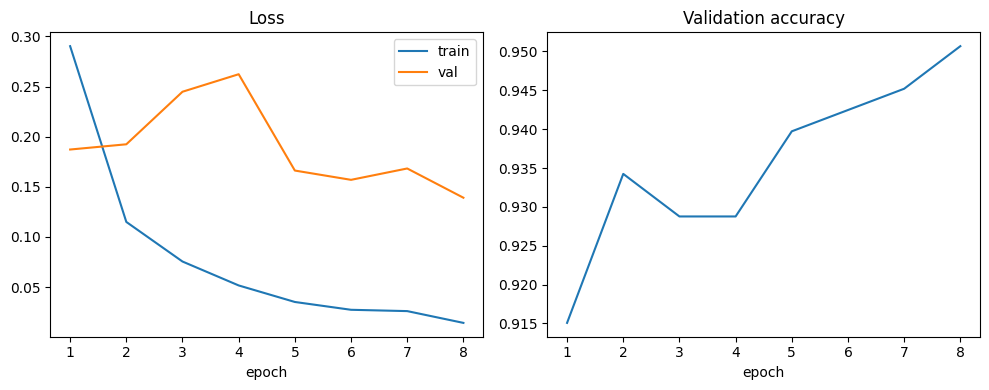

best validation accuracy: 0.951


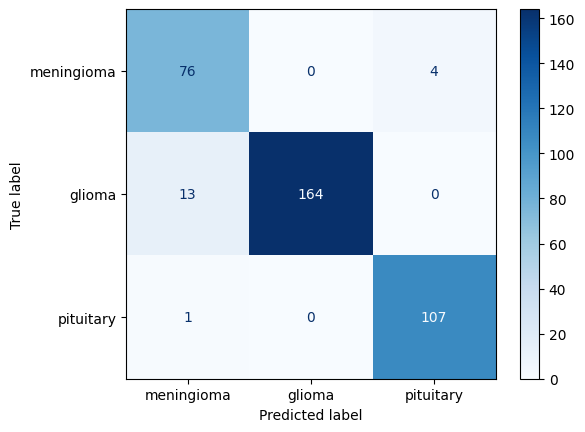

In [8]:
h = pd.DataFrame(history)
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].plot(h.epoch, h.train_loss, label="train"); ax[0].plot(h.epoch, h.val_loss, label="val")
ax[0].set_title("Loss"); ax[0].set_xlabel("epoch"); ax[0].legend()
ax[1].plot(h.epoch, h.val_acc); ax[1].set_title("Validation accuracy"); ax[1].set_xlabel("epoch")
plt.tight_layout()
plt.savefig("/kaggle/working/training_curves.png", dpi=150)
plt.show()

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
model.load_state_dict(torch.load("/kaggle/working/resnet18_best.pth"))
val_acc, _, preds, trues = evaluate(val_dl)
print("best validation accuracy:", round(val_acc, 3))
cm = confusion_matrix(trues, preds)
ConfusionMatrixDisplay(cm, display_labels=class_names).plot(cmap="Blues")
plt.savefig("/kaggle/working/val_confusion.png", dpi=150)
plt.show()

In [9]:
from sklearn.metrics import classification_report

print(classification_report(trues, preds, target_names=class_names, digits=3))

val_df = df.iloc[idx["val"]].copy()
val_df["true"], val_df["pred"] = trues, preds
errors = val_df[val_df.true != val_df.pred]
print(errors.groupby(["pid", "class_name"]).size().sort_values(ascending=False))

              precision    recall  f1-score   support

  meningioma      0.844     0.950     0.894        80
      glioma      1.000     0.927     0.962       177
   pituitary      0.964     0.991     0.977       108

    accuracy                          0.951       365
   macro avg      0.936     0.956     0.944       365
weighted avg      0.955     0.951     0.952       365

pid        class_name
100820     glioma        10
107494     meningioma     3
MR017260F  glioma         2
103925     meningioma     1
110518     pituitary      1
MR040240   glioma         1
dtype: int64


17 slices; predictions: {'meningioma': 10, 'glioma': 7}


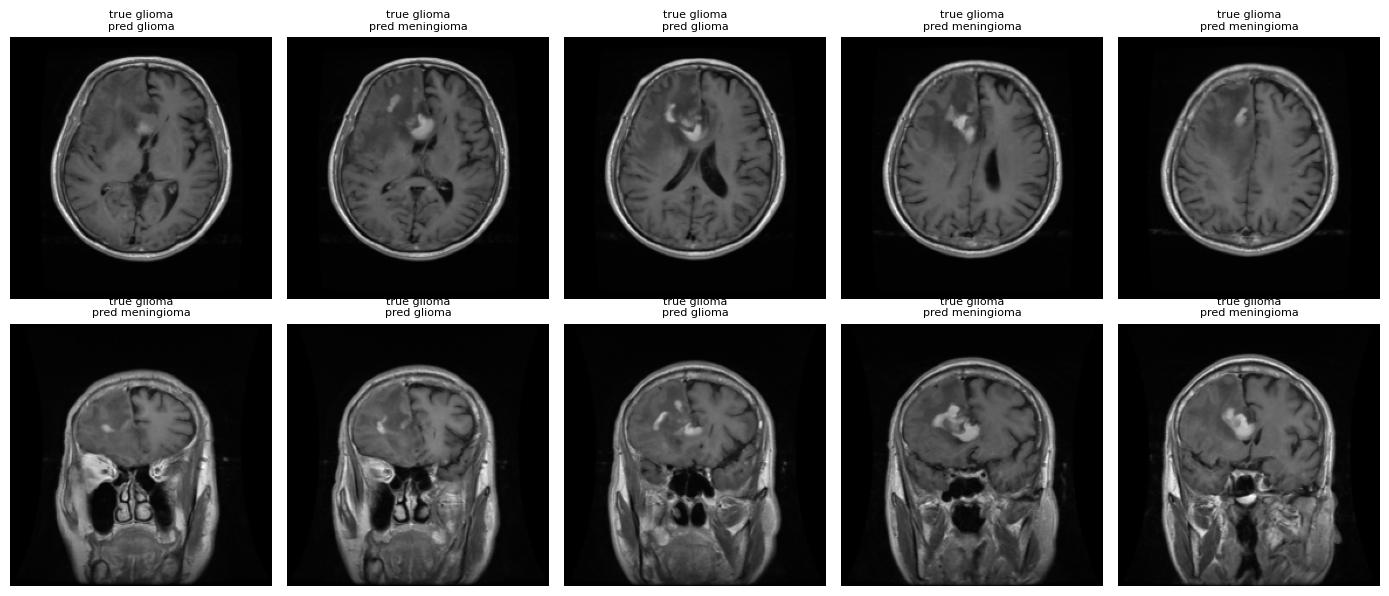

In [10]:
pid_to_check = "100820"
rows = val_df[val_df.pid == pid_to_check]
print(len(rows), "slices; predictions:", rows["pred"].map(dict(enumerate(class_names))).value_counts().to_dict())

fig, axes = plt.subplots(2, 5, figsize=(14, 6))
for ax in axes.ravel():
    ax.axis("off")
for ax, (i, r) in zip(axes.ravel(), rows.head(10).iterrows()):
    ax.imshow(X[i, 0], cmap="gray")
    ax.set_title(f"true {class_names[r.true]}\npred {class_names[r.pred]}", fontsize=8)
plt.tight_layout()
plt.show()